# Broadband CMOS RGB image sensor

BeamZ reproduction of the [published Tidy3D sensor](https://www.flexcompute.com/tidy3d/examples/notebooks/CMOSRGBSensor/), using exact embedded material coefficients and causal diagonal polarized averaging. One broadband device run plus one empty-cell calibration measures 200 frequencies; there is no wavelength sweep.

This run uses the **locally reconstructed reference depth grid and external absorber placement**, with 20 nm lateral spacing to fit the RTX3090. Reconstruction used the snapshot's exact Tidy3D version and did not submit a cloud simulation. The full reference lateral mesh is finer, so this is not a common-mesh comparison. Original numerical reference output spectra are unavailable; published-plot comparisons remain approximate.

Optical efficiency is detector-aperture power divided by incident power on the complete 3 × 3 µm unit cell. Green sums both green apertures. The detector planes and material coefficients remain fixed.

This execution includes the integer-step DFT clock fix, one-sided H reconstruction at the unchanged silicon detector plane, and native-field forward-wave incident calibration. The [cause-isolation notebook](cmos_cause_isolation.ipynb) separates their effects and shows analytical convergence controls.

In [1]:
from pathlib import Path
import os
import sys
import json
import time
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import jax
import beamz as bz

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "examples/cmos_rgb_sensor.py").exists())
sys.path.insert(0, str(root / "examples"))
from cmos_rgb_sensor import make_sim, load_materials, pixel_signs, plot_rgb_fields, reference_incident_power, Lx, Ly

print("JAX devices:", jax.devices())
test_mode = os.environ.get("BEAMZ_DOCS_TEST") == "1"
dx = (100 if test_mode else 20) * bz.nm
run_time = (100 if test_mode else 510) * 1e-15
num_freqs = 31 if test_mode else 200
frequencies = np.linspace(bz.LIGHT_SPEED/(700*bz.nm), bz.LIGHT_SPEED/(400*bz.nm), num_freqs)
wavelengths = bz.LIGHT_SPEED / frequencies

use_reference_depth_grid = not test_mode
output = root / "docs/reviews/cmos-isolation" / ("test-notebook" if test_mode else "notebook")
output.mkdir(parents=True, exist_ok=True)


JAX devices: [CudaDevice(id=0)]


## Exact reference materials

All seven material models come from the simulation embedded in the published page, saved locally with provenance and checksums. Pole/residue frequency units are SI rad/s. The RGB passbands must satisfy k ≤ 0.02 on the target CSV transparent bands; the actual central values are near 0.01.

The embedded aluminum has four real pole pairs, unlike the five-pair library model previously used. Matching names alone did not reproduce its optical response. The old models are preserved for comparison. Causal diagonal averaging uses arithmetic tangential and harmonic normal permittivity, realized with constituent polarization states. This includes dispersive interfaces and metals, but differs from the reference metal-staircasing policy. Spatial convergence and monitor colocation remain independent checks.

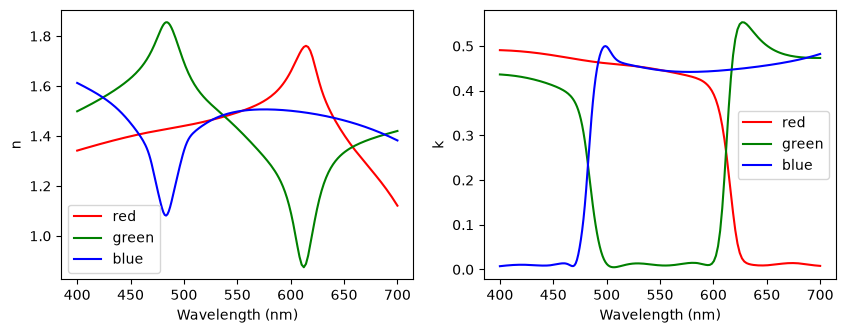

red at 650 nm: n=1.4045, k=0.00917
green at 550 nm: n=1.4304, k=0.00904
blue at 450 nm: n=1.4516, k=0.01016
Aluminum epsilon at 550 nm: (-21.901043344449196+74.8586471102467j)


In [2]:
materials = load_materials()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, color in (("red", "r"), ("green", "g"), ("blue", "b")):
    nk = np.sqrt(materials[name].eps_model(frequencies))
    axes[0].plot(wavelengths / bz.nm, nk.real, color, label=name)
    axes[1].plot(wavelengths / bz.nm, nk.imag, color, label=name)
for axis, label in zip(axes, ("n", "k")):
    axis.set(xlabel="Wavelength (nm)", ylabel=label)
    axis.legend()
plt.show()
for channel, wl in (("red",650),("green",550),("blue",450)):
    nk = np.sqrt(materials[channel].eps_model(bz.LIGHT_SPEED/(wl*bz.nm)))
    print(f"{channel} at {wl} nm: n={nk.real:.4f}, k={nk.imag:.5f}")
print("Aluminum epsilon at 550 nm:", materials["metal"].eps_model(bz.LIGHT_SPEED / (550*bz.nm)))


## Geometry and setup

The 3 × 3 µm RGGB unit cell includes four silica lens caps, filters, an aluminum shield with a circular opening, interconnects, a SiN antireflection layer, and an amorphous-silicon detector. The shield opening uses an explicit z coordinate. The SiN thickness is evaluated from its optical index at 550 nm.

The reference z grid extends the physical box by 2.19549 µm above and 0.465116 µm below for its 40-cell absorbers. Silicon continues through the lower absorber. Earlier BeamZ runs placed a 400 nm absorber inside the physical box; those results are retained as historical controls.

The timestep, Gaussian pulse offset and cubic absorber strength also follow the saved reference. Absorber conductivity is converted from its documented normalized units to SI; this does not assert identical internal boundary operators between solvers.

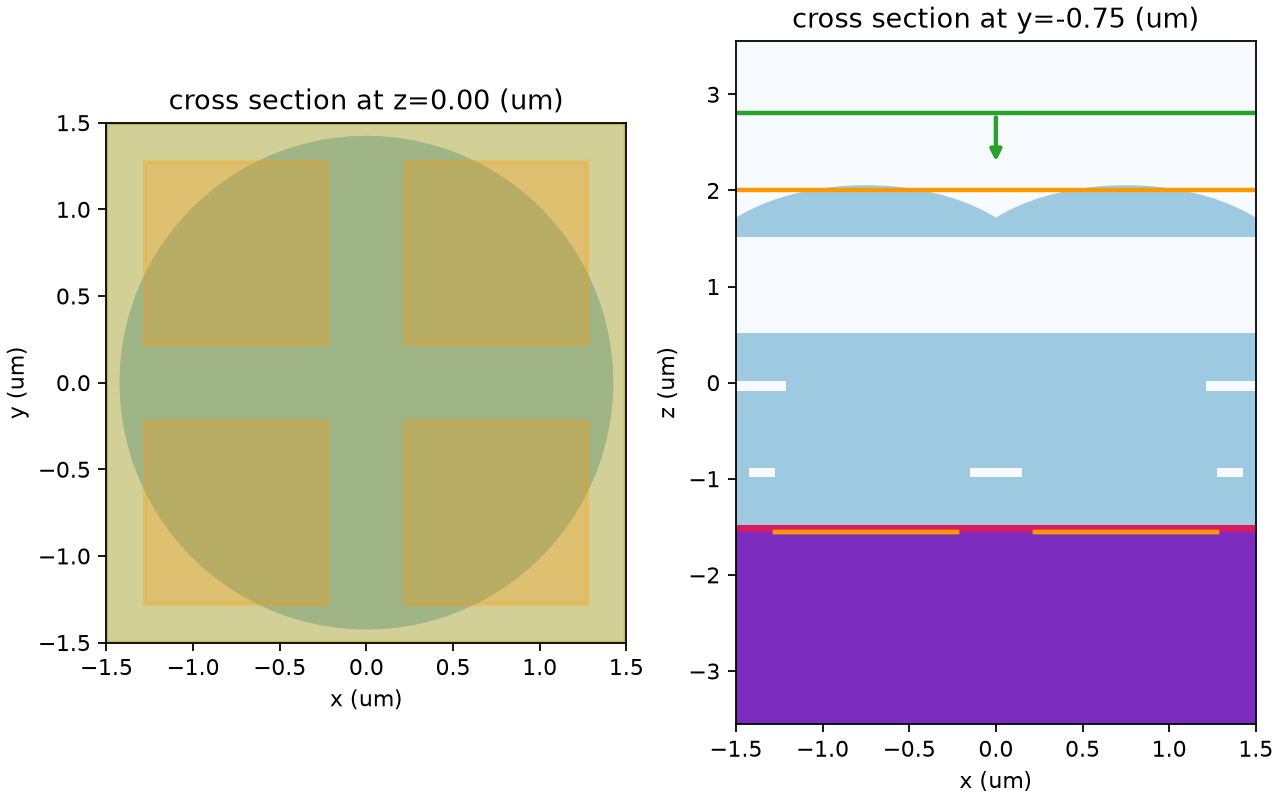

Analytic preview of the optical geometry inside the physical domain; external absorber layers are omitted from this illustration. The simulation uses the imported reference scene.


In [3]:
setup_start = time.perf_counter()
simulation = make_sim(dx=dx, run_time=run_time, num_freqs=num_freqs,
                      reference_z=use_reference_depth_grid,
                      colocation_side="plus" if use_reference_depth_grid else None)
setup_seconds = time.perf_counter() - setup_start
print("Grid:", simulation.grid.shape, "steps:", simulation.num_steps, "dt:", simulation.dt)



Grid: (150, 150, 430) steps: 35385 dt: 1.4413465606999474e-17


## Run the broadband device

Flux monitors collect 200 reference frequencies; field monitors collect all three electric components at 450, 550, and 650 nm. The 510 fs run records an intermediate 300 fs spectrum to assess late-time change. This does not use nondispersive energy-based termination for dispersive materials.

In [4]:
def run_and_save(sim, name):
    checkpoint = int(min(300e-15, 0.6*run_time) / sim.dt)
    start = time.perf_counter()
    first = sim.advance(num_steps=checkpoint, backend="jax", performance=False)
    first_seconds = time.perf_counter() - start
    print(f"{name}: checkpoint reached", flush=True)
    start = time.perf_counter()
    final = sim.advance(state=first.state, num_steps=sim.num_steps-checkpoint,
                        backend="jax", performance=False, donate_state=True)
    final_seconds = time.perf_counter() - start
    result = final.results
    raw = {pixel: -np.asarray(result[f"flux_si_{pixel}"].flux) for pixel in pixel_signs}
    earlier = {pixel: -np.asarray(first.results[f"flux_si_{pixel}"].flux) for pixel in pixel_signs}
    report = dict(device=str(jax.devices()), dx_nm=float(np.diff(sim.grid.x_edges)[0]/bz.nm), runtime_fs=run_time*1e15,
                  grid=list(sim.grid.shape), steps=int(sim.num_steps), dt=float(sim.dt),
                  reference=name=="reference", smoothing="farjadpour_diagonal",
                  reference_z=use_reference_depth_grid, boundary="absorber",
                  clock_policy="integer_step", detector_colocation="plus" if use_reference_depth_grid else None,
                  checkpoint_fs=checkpoint*float(sim.dt)*1e15,
                  first_half_seconds=first_seconds, second_half_seconds=final_seconds,
                  finite_fields=all(np.isfinite(np.asarray(getattr(final.state,c))).all().item()
                                    for c in ("ex","ey","ez","hx","hy","hz")),
                  finite_polarization=all(np.isfinite(np.asarray(q)).all().item()
                                         for q in final.state.polarization),
                  temporal_max_absolute_change={p:float(np.max(abs(raw[p]-earlier[p]))) for p in raw},
                  material_checksums={name:hashlib.sha256((root/"examples/data/cmos_rgb"/name).read_bytes()).hexdigest()
                                      for name in ("materials.json","filters.json")})
    report["absorbers"] = [dict(edges=b.edges, thickness=b.thickness, sigma_max=b.sigma_max, m=b.m)
                           for b in sim.boundaries if isinstance(b, bz.Absorber)]
    report["source_offset"] = sim.sources[0].source_time.offset
    report["grid_sha256"] = {axis:hashlib.sha256(edges.tobytes()).hexdigest()
                             for axis,edges in zip("xyz",sim.grid.edges)}
    assert report["finite_fields"] and report["finite_polarization"]
    np.savez(output/f"{name}_spectra.npz", wavelength_nm=wavelengths/bz.nm,
             incident_plane=-np.asarray(result["incident_plane"].flux), **raw)
    np.savez(output/f"{name}_checkpoint_spectra.npz", wavelength_nm=wavelengths/bz.nm, **earlier)
    np.savez(output/f"{name}_grid.npz", **dict(zip("xyz",sim.grid.edges)))
    (output/f"{name}_report.json").write_text(json.dumps(report,indent=2)+"\n")
    return result, report

result, sensor_report = run_and_save(simulation, "sensor")
sensor_report["setup_seconds"] = setup_seconds
(output/"sensor_report.json").write_text(json.dumps(sensor_report,indent=2)+"\n")
simulation.clear_compiled_cache()
jax.clear_caches()
print("Device completed with finite fields and polarization.")


sensor: checkpoint reached


Device completed with finite fields and polarization.


## Incident-power calibration

Two native electric-field planes in uniform air separate the incident and reflected waves using the Yee dispersion relation. Their forward amplitude gives P₀(f) without interpolating staggered E and H. The former symmetric flux denominator underestimated incident power on the coarse air mesh.

The empty reference retains the same source, physical aperture, z grid, timestep and acquisition time. It uses four lateral cells per direction: transverse derivatives vanish for this normally incident empty cell. This reduction was checked against the full-width reference. One-sided detector reconstruction uses three H samples inside SiN; the physical detector plane remains fixed. Test mode retains the coarse smoke-test configuration and is not an accuracy benchmark.

reference: checkpoint reached


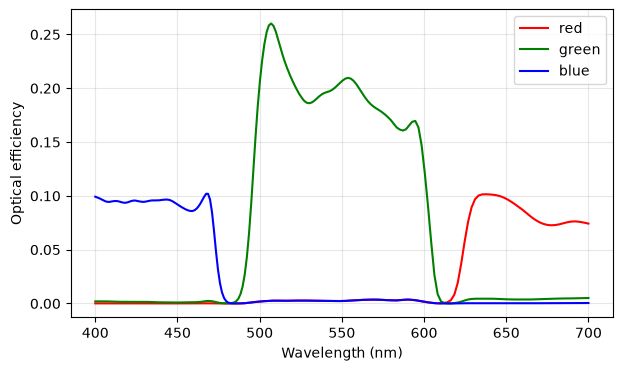

Central-wavelength optical efficiencies (computed, approximate interpolation):
red: 9.72%
green: 20.65%
blue: 9.20%
red: maximum 300-to-510 fs change = 0.0017 percentage points
green: maximum 300-to-510 fs change = 0.0146 percentage points
blue: maximum 300-to-510 fs change = 0.0017 percentage points


In [5]:
reference_simulation = make_sim(dx=750*bz.nm if use_reference_depth_grid else dx, run_time=run_time, reference=True, fields=False, num_freqs=num_freqs, reference_z=use_reference_depth_grid)
reference, reference_report = run_and_save(reference_simulation, "reference")
reference_simulation.clear_compiled_cache()
jax.clear_caches()
if use_reference_depth_grid:
    assert reference_simulation.dt == simulation.dt
    np.testing.assert_array_equal(reference_simulation.grid.z_edges, simulation.grid.z_edges)
    incident_power, backward_power = reference_incident_power(reference, reference_simulation)
    np.savez(output/"incident_calibration.npz", wavelength_nm=wavelengths/bz.nm,
             modal_power=incident_power, backward_power=backward_power,
             plane_power=-np.asarray(reference["incident_plane"].flux))
else:
    incident_power = -np.asarray(reference["incident_plane"].flux)
assert np.all(np.isfinite(incident_power)) and np.all(incident_power > 0)
efficiency = {pixel: -np.asarray(result[f"flux_si_{pixel}"].flux) / incident_power for pixel in pixel_signs}
fig, ax = plt.subplots(figsize=(7, 4))
for name, color in (("red", "r"), ("green", "g"), ("blue", "b")):
    values = efficiency["green1"] + efficiency["green2"] if name == "green" else efficiency[name]
    ax.plot(wavelengths / bz.nm, values, color, label=name)
ax.set(xlabel="Wavelength (nm)", ylabel="Optical efficiency")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Central-wavelength optical efficiencies (computed, approximate interpolation):")
for channel, wl in (("red",650),("green",550),("blue",450)):
    y = efficiency["green1"] + efficiency["green2"] if channel == "green" else efficiency[channel]
    order = np.argsort(wavelengths)
    value = np.interp(wl*bz.nm, wavelengths[order], y[order])
    print(f"{channel}: {100*value:.2f}%")
# Save numerical outputs for the cross-grid comparison.
np.savez(output/"calibrated_efficiency.npz", wavelength_nm=wavelengths/bz.nm,
         red=efficiency["red"], green=efficiency["green1"]+efficiency["green2"], blue=efficiency["blue"])

with np.load(output/"sensor_checkpoint_spectra.npz") as checkpoint:
    for channel in ("red","green","blue"):
        early = checkpoint["green1"]+checkpoint["green2"] if channel=="green" else checkpoint[channel]
        late = efficiency["green1"]+efficiency["green2"] if channel=="green" else efficiency[channel]
        print(f"{channel}: maximum 300-to-510 fs change = {100*np.max(abs(late-early/incident_power)):.4f} percentage points")
fig.savefig(output/"calibrated_efficiency.png", dpi=160)


## Total electric-field intensity

These plots show **(|Ex|² + |Ey|² + |Ez|²) / |Eincident|²**, using native-field forward incident power for calibration. All three wavelength panels in each row share the same color scale. This replaces the earlier Ex-only plots. The reference webpage's absolute field plots use a different display normalization; these dimensionless maps make spatial and spectral comparisons interpretable.

The plots use the public DFT field accessor, including its acquisition-weight normalization. Numerical field arrays and physical plotting coordinates are saved alongside the figures. Field monitors retain standard spatial interpolation; interface-normal E still requires a separate spatial-convergence check.

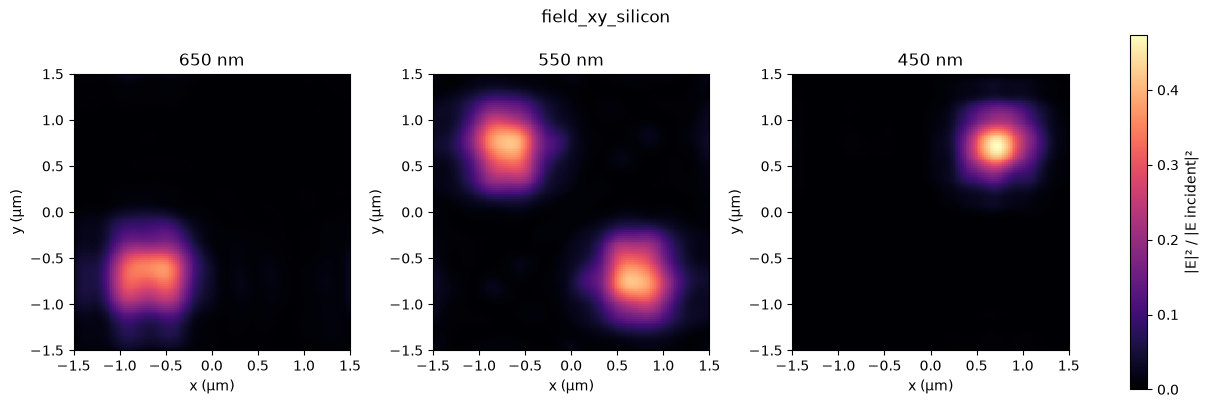

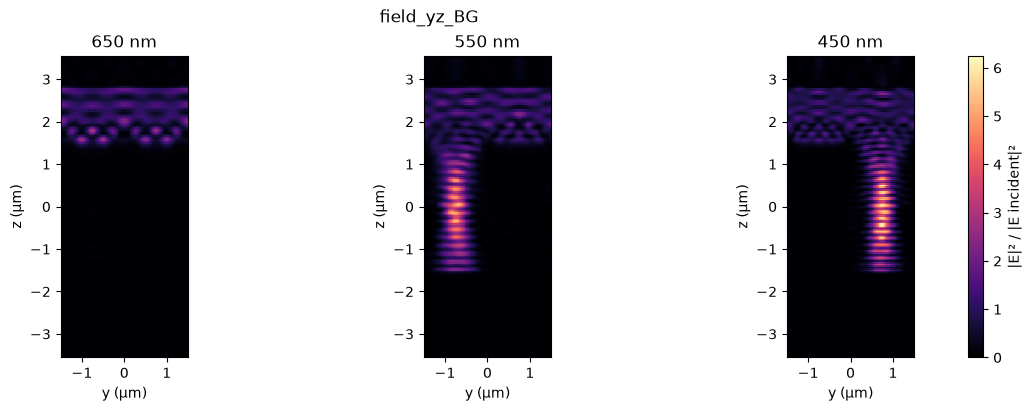

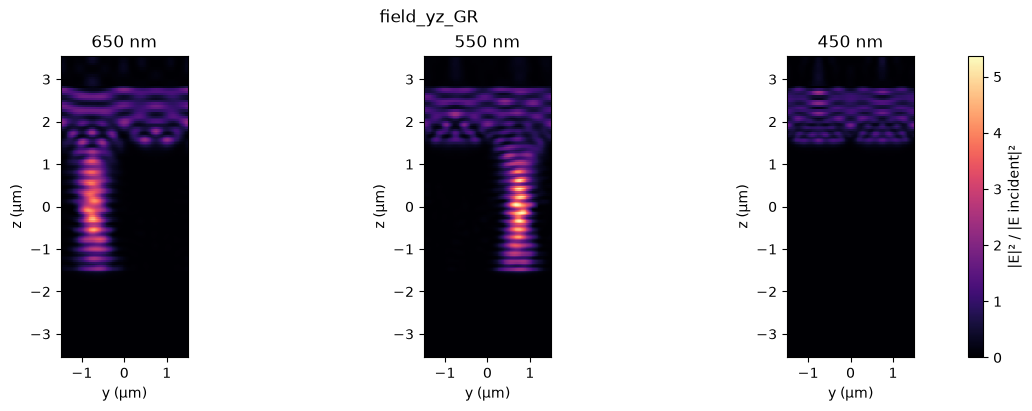

In [6]:
order = np.argsort(wavelengths)
incident_intensity = (2*np.sqrt(bz.MU_0/bz.EPS_0)/(Lx*Ly)
                      * np.interp(np.array([650,550,450])*bz.nm,
                                  wavelengths[order], incident_power[order]))
figures = plot_rgb_fields(result, reference, incident_intensity=incident_intensity)
for name, fig in zip(("field_xy_silicon", "field_yz_BG", "field_yz_GR"), figures):
    fig.savefig(output/f"{name}.png", dpi=150)
    monitor = result[name]
    axes_names = ("x","y") if name=="field_xy_silicon" else ("y","z")
    coords = {}
    for axis in axes_names:
        interval = monitor.sample_region.axis_interval(axis)
        edges = result.metadata.grid.axis_edges(axis)[interval.start:interval.stop+1]
        coords[f"{axis}_edges_um"] = (edges-result.metadata.coordinate_offset["xyz".index(axis)])/bz.um
    np.savez_compressed(output/f"{name}.npz", wavelength_nm=np.array([650,550,450]),
                        incident_intensity=incident_intensity, **coords,
                        **{c:np.asarray(monitor.get_dft_component(c),dtype=np.complex64) for c in ("Ex","Ey","Ez")})
plt.show()

## Validation and remaining limits

- Exact imported materials are checked against the saved simulation snapshot.
- Causal diagonal interface tests cover Drude/Lorentz/static limits, normal and tangential response, equal epsilon-infinity, pure fractions, continuation and periodic seams. Oblique TE/TM half-space controls separately check physical flux accuracy.
- The reconstructed z mesh and absorber placement match the snapshot; lateral spacing and metal interface policy differ. This is not an exact solver-parity certificate.
- One-sided H reconstruction avoids crossing the silicon interface; its stencil must remain in a smooth region. The detector plane is unchanged. A broadband silicon half-space control and refined multilayer transfer-matrix controls verify accuracy separately.
- Finite fields, time convergence and material parity do not establish spatial convergence. See `docs/reviews/cmos-isolation` for raw spectra, run metadata and analytical checks.


## Comparison and interpretation

The table below separates the historical reference-z result from this corrected execution. Published Tidy3D values are approximate readings of its plot, not numerical reference data. Green sums both detector apertures. Neither numerical stability nor a single mesh establishes full-sensor convergence.

The separate [cause-isolation notebook](cmos_cause_isolation.ipynb) contains paired detector measurements, native incident calibration, component removal controls and planar depth convergence. Exact Tidy3D output arrays and matched component runs are still needed to attribute the remaining inter-solver gap.

In [7]:
from IPython.display import Markdown, display
channels = (("red",650),("green",550),("blue",450))
old = np.load(root/"docs/reviews/cmos-polarized/reference-z-20nm-absorber/calibrated_efficiency.npz")
def centers(data, wavelength_nm):
    idx=np.argsort(wavelength_nm)
    return [100*np.interp(w, wavelength_nm[idx], data[c][idx]) for c,w in channels]
current = dict(red=efficiency["red"],green=efficiency["green1"]+efficiency["green2"],blue=efficiency["blue"])
rows = [("Historical reference z", centers(old,old["wavelength_nm"])),
        ("Corrected execution", centers(current,wavelengths/bz.nm))]
table = "| Run | Red, 650 nm | Green, 550 nm | Blue, 450 nm |\n|---|---:|---:|---:|\n"
for label, values in rows:
    table += "| " + label + " | " + " | ".join(f"{v:.3f}%" for v in values) + " |\n"
table += "| Published plot (approximate) | ~6% | ~20% | ~6% |"
display(Markdown(table))

| Run | Red, 650 nm | Green, 550 nm | Blue, 450 nm |
|---|---:|---:|---:|
| Historical reference z | 9.785% | 20.615% | 8.849% |
| Corrected execution | 9.725% | 20.652% | 9.203% |
| Published plot (approximate) | ~6% | ~20% | ~6% |